***Week 10 Jupyter Notebook — Assignment Instructions***

Each week, apply the concepts to the Integrated Capstone Project dataset in a Jupyter Notebook, analyze the data and draw interesting conclusions. For this week, include **k-means, the elbow method, silhouette scores, feature scaling and distance metrics**. Complete the homework by 11:59pm ET on Sunday. In Week 12, compile findings into Milestone Two.

**Yellowdig:** showcase at least one high-quality source, link/cite it and explain its quality; investigate and respectfully respond to peers' sources. A draft initial post is included below. Peer replies require the actual peer posts and are not fabricated.

The referenced **Mod C Milestone Two Guidelines and Rubric** link/content was not supplied, so rubric-specific coverage cannot be verified. This notebook addresses the supplied concepts; course submission is separate.

# Week 10: K-means, scaling and cluster selection

Calvin Baker · DX799 Integrated Capstone · Three independent datasets

## tl;dr

- **Loan Default (n=2,000):** standard-scaled k-means selects **k=2**, silhouette **0.416**; the chord elbow suggests **k=4**. Loan term shows the largest standardized center difference. Cluster status rates are almost identical (**23.6%–23.8%**), so geometric separation does not imply useful default separation.
- **LendingClub (n=2,000):** k=2 has silhouette **0.177**, versus an elbow candidate of k=4. The groups overlap; **4.3%** of records have negative silhouette. Log income has the largest absolute standardized center, and charge-off fractions range **12.0%–14.2%** descriptively.
- **Bank (n=39):** k=2 has silhouette **0.488**, with groups of **11 and 28** records. This small record-level study illustrates age/tenure geometry, not population customer segments.
- Repeated initializations largely agree (minimum seed ARI **1.000 / 0.996 / 1.000** respectively). Scaling and distance diagnostics answer different geometry questions; initialization agreement does not establish stability across samples. Outcome labels are excluded from clustering and selection.

These are results from the delivered run. The three datasets have different populations and features; compare methods within a dataset.

## Context & Methods

**Question:** What borrower/account profiles emerge without fitting an outcome label, and how much do the groups depend on geometry and algorithm choices?

### Key Assumptions

- Analyze the three CSVs independently. Reconstruct Week 9's 12,000-row loan samples, then take a seed-42 uniform subsample of 2,000 per loan dataset; use all eligible bank records. Week 10 and Week 11 use identical numeric feature rows. This changes the analysis population from the full supervised experiments.
- Loan_Default uses loan amount, income, credit score and term. LendingClub uses log1p loan amount, log1p income, FICO midpoint, debt-to-income ratio, revolving utilization and open-account count. Bank uses age and historical tenure in years. Categorical features are omitted to keep the distance weighting explicit; groups describe only this numeric view.
- Keep the prior resolved-2015, 36-month LendingClub cohort for continuity. Conditioning on resolution limits the population; these clusters do not describe all originations. Loan_Default status timing remains undocumented. Bank eligibility/reference date stays **September 26, 2026** for comparability, not the execution date.
- Median imputation and scaling fit this exploratory sample. There is no held-out predictive performance claim. Outcomes (recorded status, charge-off, checking type) never enter distances or parameter selection, but the LendingClub cohort itself depends on resolution status.
- Standard scaling is the primary geometry. It gives features equal variance, not equal business relevance, and remains sensitive to extremes. No silent winsorization. Repeated or correlated features can change effective weighting. Bank rows may repeat accounts and are not established independent customers.
- At least max(3, ceil(1% of sample size)) records per cluster is an explicit exploratory size rule. Candidate ranges are bounded choices, not exhaustive searches or discovered truths. Do not use demographic profiles or cluster labels as credit decisions.

## Data

Original inputs are local `DATA/Loan_Default.csv`, `DATA/accepted_2007_to_2018Q4.csv` and `DATA/bank_customers.csv`. No external data are added. Audits below reconcile source/cohort/sample counts and print a feature fingerprint for matching the weeks. SSNs are not loaded; identifiers and exact dates are not displayed or used as numeric features.

### 1. Set up a reproducible environment

Use the repository’s `requirements-notebooks.txt`. Run from the repository or its parent. Each notebook is self-contained; no prior fitted objects or cached data are required.

In [1]:
from pathlib import Path
import platform
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score, pairwise_distances
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree, cophenet
from scipy.spatial.distance import pdist
from threadpoolctl import threadpool_limits

SEED = 42
SAMPLE_SIZE = 12_000  # Reconstruct the prior week's cohorts before clustering subsampling.
CLUSTER_SAMPLE = 2_000  # Same rows for both weeks; bounds pairwise-memory/time costs.
thread_limit = threadpool_limits(limits=1)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.figsize': (10, 4.5), 'figure.dpi': 110,
    'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': .15, 'axes.axisbelow': True})
DATA_DIR = next((p for p in [Path.cwd()/'DATA',
    Path.cwd()/'Data-Science-Capstone-DX799'/'DATA'] if p.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Run from the repository or its parent; original DATA files are required.')
display(pd.Series({'Python': platform.python_version(), 'NumPy': np.__version__,
    'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
    'SciPy': scipy.__version__, 'seed': SEED}, name='Execution environment'))
results = []

Python          3.13.5
NumPy            2.4.1
pandas           3.0.0
scikit-learn     1.8.0
SciPy           1.17.0
seed                42
Name: Execution environment, dtype: object

### 2. Define shared analysis helpers

In [2]:
def cluster_stats(labels):
    labels = np.asarray(labels)
    counts = pd.Series(labels[labels != -1]).value_counts()
    return {'clusters': len(counts), 'noise fraction': float(np.mean(labels == -1)),
            'smallest cluster': int(counts.min()) if len(counts) else 0,
            'largest share': float(counts.max()/len(labels)) if len(counts) else 0.0}

def safe_silhouette(data, labels):
    # DBSCAN noise is excluded explicitly; a single remaining cluster is undefined.
    mask = np.asarray(labels) != -1
    lab = np.asarray(labels)[mask]
    if not 2 <= len(np.unique(lab)) < len(lab):
        return np.nan
    return silhouette_score(data[mask], lab, metric='euclidean')

def profile(labels, title):
    # Original analysis units; log variables remain log1p units, not dollars.
    table = X.assign(cluster=labels, **{'profile outcome': y.to_numpy()}).groupby('cluster').agg(
        n=('profile outcome', 'size'), **{'outcome fraction': ('profile outcome', 'mean')})
    table = table.join(X.assign(cluster=labels).groupby('cluster').median().add_prefix('median '))
    assert table['n'].sum() == len(X)
    display(Markdown(f'**{title}.** Outcome fraction = {outcome_label}; descriptive only.'))
    display(table)
    return table

def scatter_clusters(coords, labels, ax, title):
    markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '<', '>']
    for i, label in enumerate(sorted(np.unique(labels))):
        mask = labels == label
        noise = label == -1
        ax.scatter(coords[mask, 0], coords[mask, 1], s=20 if len(coords)>100 else 45,
            alpha=.65, marker='x' if noise else markers[i % len(markers)],
            color='#666666' if noise else plt.get_cmap('tab10')(i % 10),
            label='Noise' if noise else f'C{label} (n={mask.sum()})')
    ax.set(title=title, xlabel='PC1 (standardized-feature projection)', ylabel='PC2')
    ax.legend(fontsize=8, loc='best', ncol=2)

## Results: method guide

K-means assigns each record to a centroid and minimizes the sum of squared Euclidean distances (inertia). Increasing k tends to reduce inertia even without useful structure; an elbow is a diminishing-return heuristic. We examine k=1–8 for inertia and k=2–8 for silhouette, then choose the largest standard-space silhouette meeting the size rule. Twenty initializations reduce local-minimum sensitivity.

For record i, silhouette is (b−a)/max(a,b), where a is mean within-cluster distance and b the smallest mean distance to another cluster. Values near one indicate separation, near zero indicate overlap and negative values indicate closer alternatives. It is undefined for a single cluster. All scores below are exact on the bounded sample.

Unscaled, standard and robust representations are compared. Robust scaling uses medians and interquartile ranges; it does not remove outliers. Inertia cannot be compared numerically across units/representations. Fixed-k ARI separates changes in assignments from changes in k.

References: [KMeans](https://scikit-learn.org/1.8/modules/generated/sklearn.cluster.KMeans.html), [silhouette_score](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.silhouette_score.html), [StandardScaler](https://scikit-learn.org/1.8/modules/generated/sklearn.preprocessing.StandardScaler.html).

## A. Loan_Default.csv

### A1. Reconstruct the source cohort

In [3]:
dataset_name = 'Loan_Default.csv'
outcome_label = 'recorded Status 1'
source_frame = pd.read_csv(DATA_DIR / dataset_name)
assert source_frame['ID'].notna().all() and source_frame['ID'].is_unique
assert source_frame['Status'].notna().all() and set(source_frame['Status'].unique()) == {0,1}
assert not source_frame.duplicated().any()
# Uniform sampling is independent of outcome. Preserve original indices for audits.
frame = source_frame.sample(n=min(SAMPLE_SIZE, len(source_frame)), random_state=SEED).copy()
numeric = ['loan_amount', 'income', 'Credit_Score', 'term']
categorical = ['loan_type', 'loan_purpose', 'occupancy_type']
X = frame[numeric + categorical].copy()
for name in categorical:
    X[name] = X[name].astype(object).where(X[name].notna(), np.nan)
y = frame['Status'].astype(int)
groups = None
display(pd.Series({'source rows':len(source_frame), 'valid target rows':len(source_frame),
    'uniform modeling sample':len(frame), 'not sampled':len(source_frame)-len(frame)}, name='Source reconciliation'))

source rows                148670
valid target rows          148670
uniform modeling sample     12000
not sampled                136670
Name: Source reconciliation, dtype: int64

### A2. Audit the shared clustering sample

In [4]:
# Use numeric features only: categorical one-hot block weights would add a separate geometry choice.
X = X[numeric].replace([np.inf, -np.inf], np.nan).reset_index(drop=True)
y = y.reset_index(drop=True)
indices = (X.sample(n=CLUSTER_SAMPLE, random_state=SEED).index.to_numpy()
           if len(X) > CLUSTER_SAMPLE else np.arange(len(X)))
X = X.iloc[indices].reset_index(drop=True)
y = y.iloc[indices].reset_index(drop=True)
assert not X.isna().all().any(), 'An entirely missing feature needs a documented decision.'
assert X.select_dtypes('number').shape[1] == X.shape[1]
imputer = SimpleImputer(strategy='median')
raw = imputer.fit_transform(X)
scaler = StandardScaler()
Z = scaler.fit_transform(raw)
assert np.isfinite(Z).all() and len(X) == len(y)
min_cluster = max(3, int(np.ceil(.01*len(X))))
plot_label = {'Loan_Default.csv':'Loan Default', 'accepted_2007_to_2018Q4.csv':'LendingClub',
              'bank_customers.csv':'Bank records'}[dataset_name]
fingerprint = hashlib.sha256(pd.util.hash_pandas_object(X, index=False).values.tobytes()).hexdigest()[:16]
display(pd.Series({'clustering records': len(X), 'numeric dimensions': X.shape[1],
    'duplicate feature rows': X.duplicated().sum(), 'minimum acceptable cluster size': min_cluster,
    'sample feature fingerprint': fingerprint}, name='Clustering sample'))
display(pd.DataFrame({'missing n': X.isna().sum(), 'median': X.median(),
    'minimum': X.min(), 'maximum': X.max(), 'SD before scaling': pd.DataFrame(raw, columns=X.columns).std()}))
pca = PCA(n_components=2, svd_solver='full')
coords = pca.fit_transform(Z)
display(Markdown(f'PCA shows **{pca.explained_variance_ratio_.sum():.1%}** of standardized variance. '
    'All clustering and scores use the full feature space, not this display projection.'))

clustering records                             2000
numeric dimensions                                4
duplicate feature rows                            1
minimum acceptable cluster size                  20
sample feature fingerprint         de56ac5c17ea8ad6
Name: Clustering sample, dtype: object

,missing n,median,minimum,maximum,SD before scaling
loan_amount,0,"296,500.000","26,500.000","1,926,500.000","176,940.049"
income,114,"5,580.000",0.000,"67,680.000","5,156.540"
Credit_Score,0,708.000,500.000,900.000,114.741
term,0,360.000,96.000,360.000,59.162


PCA shows **63.7%** of standardized variance. All clustering and scores use the full feature space, not this display projection.

### A3. Compare k, elbow and scaling

,representation,k,inertia,silhouette,clusters,noise fraction,smallest cluster,largest share
0,Unscaled,1,"62,637,440,735,846.812",NaN,1,0.000,2000,1.000
1,Unscaled,2,"23,209,264,757,374.672",0.598,2,0.000,693,0.653
2,Unscaled,3,"13,145,609,795,990.111",0.567,3,0.000,250,0.483
3,Unscaled,4,"8,981,170,810,658.027",0.564,4,0.000,10,0.459
4,Unscaled,5,"5,346,442,624,351.260",0.551,5,0.000,10,0.340
5,Unscaled,6,"3,791,049,874,793.181",0.541,6,0.000,10,0.275
6,Unscaled,7,"2,881,953,971,583.757",0.545,7,0.000,10,0.251
7,Unscaled,8,"2,288,010,061,382.590",0.538,8,0.000,10,0.224
8,Standard,1,"8,000.000",NaN,1,0.000,2000,1.000
9,Standard,2,"6,056.727",0.416,2,0.000,284,0.858


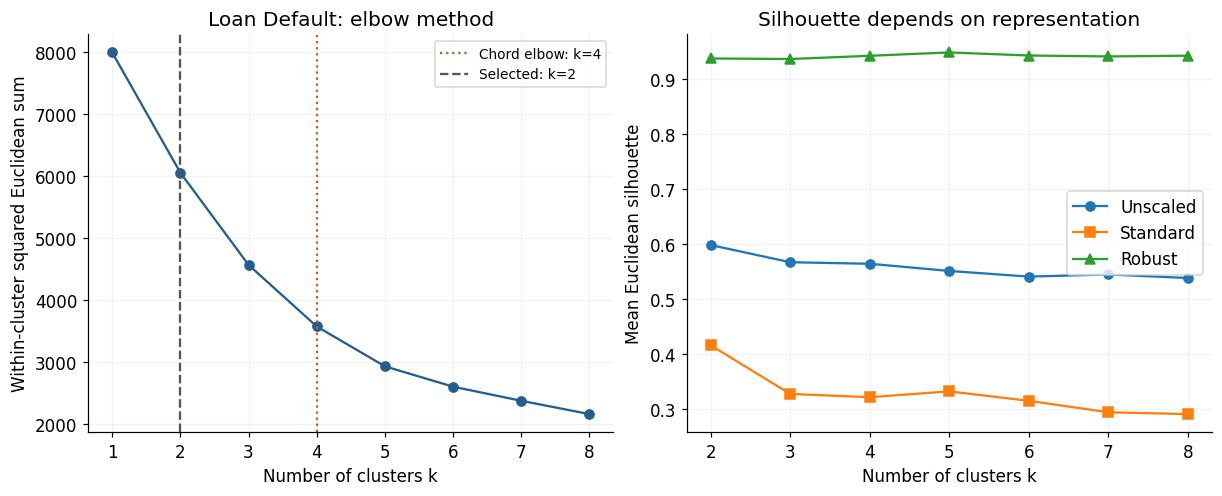

**Selection:** standard-scaled k=2, silhouette **0.416**, smallest cluster **284**; chord elbow suggests **k=4**. The largest eligible silhouette selects k; the elbow is a second diagnostic, not proof of a true number of groups. Scores across representations evaluate different geometries and cannot establish a universally best scaler.

In [5]:
representations = {'Unscaled': raw, 'Standard': Z, 'Robust': RobustScaler().fit_transform(raw)}
k_grid = range(1, 9)
k_rows, fitted = [], {}
for representation, data in representations.items():
    distances = pairwise_distances(data, metric='euclidean')
    np.fill_diagonal(distances, 0)
    for k in k_grid:
        model = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(data)
        fitted[(representation, k)] = model
        stats = cluster_stats(model.labels_)
        score = silhouette_score(distances, model.labels_, metric='precomputed') if k>1 else np.nan
        k_rows.append({'representation': representation, 'k': k, 'inertia': model.inertia_,
                       'silhouette': score, **stats})
k_table = pd.DataFrame(k_rows)
display(k_table.round(4))
standard = k_table.query("representation == 'Standard'").copy()
candidates = standard.query('k >= 2 and `smallest cluster` >= @min_cluster')
assert len(candidates), 'No supported standard-scaled candidate; revise the exploratory scope explicitly.'
chosen = candidates.sort_values(['silhouette','k'], ascending=[False,True]).iloc[0]
chosen_k = int(chosen['k'])
km = fitted[('Standard', chosen_k)]
labels = km.labels_
# Maximum vertical gap from a normalized endpoint chord: a reproducible elbow heuristic.
x_norm = (standard['k'].to_numpy()-1)/7
y_norm = (standard['inertia'].to_numpy()-standard['inertia'].iloc[-1])/(standard['inertia'].iloc[0]-standard['inertia'].iloc[-1])
elbow_k = int(standard.iloc[np.argmax((1-x_norm)-y_norm)]['k'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout='constrained')
axes[0].plot(standard['k'], standard['inertia'], 'o-', color='#245E91')
axes[0].axvline(elbow_k, linestyle=':', color='#B96520', label=f'Chord elbow: k={elbow_k}')
axes[0].axvline(chosen_k, linestyle='--', color='#555555', label=f'Selected: k={chosen_k}')
axes[0].set(title=f'{plot_label}: elbow method', xlabel='Number of clusters k', ylabel='Within-cluster squared Euclidean sum')
axes[0].legend(fontsize=9)
for name, marker in [('Unscaled','o'), ('Standard','s'), ('Robust','^')]:
    part = k_table.query('representation == @name and k >= 2')
    axes[1].plot(part['k'], part['silhouette'], marker=marker, label=name)
axes[1].set(title='Silhouette depends on representation', xlabel='Number of clusters k', ylabel='Mean Euclidean silhouette')
axes[1].legend()
plt.show()
display(Markdown(f'**Selection:** standard-scaled k={chosen_k}, silhouette **{chosen["silhouette"]:.3f}**, '
    f'smallest cluster **{int(chosen["smallest cluster"])}**; chord elbow suggests **k={elbow_k}**. '
    'The largest eligible silhouette selects k; the elbow is a second diagnostic, not proof of a true number of groups. '
    'Scores across representations evaluate different geometries and cannot establish a universally best scaler.'))

### A4. Check assignments and initialization sensitivity

In [6]:
# Hold k fixed to isolate scaling sensitivity from changes in cluster count.
scaling_rows = []
for name, data in representations.items():
    model = fitted[(name, chosen_k)]
    scaling_rows.append({'representation': name, 'fixed k': chosen_k,
        'own-space silhouette': safe_silhouette(data, model.labels_),
        'ARI vs Standard': adjusted_rand_score(labels, model.labels_), **cluster_stats(model.labels_)})
display(pd.DataFrame(scaling_rows).set_index('representation'))
# Expected contribution to pairwise squared distances is proportional to feature variance.
contributions = pd.Series(raw.var(axis=0), index=X.columns)
display((contributions/contributions.sum()).rename('raw squared-distance variance share').to_frame())
stability = []
for seed in [7, 21, 42, 84, 123]:
    repeat = KMeans(n_clusters=chosen_k, n_init=20, random_state=seed).fit(Z)
    stability.append({'seed': seed, 'inertia': repeat.inertia_,
                      'ARI vs seed 42': adjusted_rand_score(labels, repeat.labels_)})
display(pd.DataFrame(stability))
display(Markdown('ARI measures agreement after allowing cluster-number permutations. '
    'This check changes initialization on the same data; it does not measure stability under new samples.'))

# Explain surprisingly high robust-space silhouettes with the actual fitted scales.
robust_audit = RobustScaler().fit(raw)
iqr = np.quantile(raw,.75,axis=0)-np.quantile(raw,.25,axis=0)
robust_var = representations['Robust'].var(axis=0)
display(pd.DataFrame({'imputed IQR':iqr, 'RobustScaler divisor':robust_audit.scale_,
    'robust squared-distance variance share':robust_var/robust_var.sum()},index=X.columns))
raw_leader = contributions.idxmax()
robust_leader = X.columns[np.argmax(robust_var)]
display(Markdown(f'**Scaling finding:** {raw_leader} contributes '
    f'{contributions.max()/contributions.sum():.1%} of raw pairwise squared-distance variation; '
    f'{robust_leader} contributes {robust_var.max()/robust_var.sum():.1%} after robust scaling. '
    'A zero IQR uses a unit divisor, so a discrete feature can retain a large numerical range. '
    'A higher silhouette in that space may reflect dominant feature weighting rather than stronger multi-feature segments.'))


,fixed k,own-space silhouette,ARI vs Standard,clusters,noise fraction,smallest cluster,largest share
representation,,,,,,,
Unscaled,2,0.598,-0.033,2,0.000,693,0.653
Standard,2,0.416,1.000,2,0.000,284,0.858
Robust,2,0.938,0.995,2,0.000,286,0.857


,raw squared-distance variance share
loan_amount,0.999
income,0.001
Credit_Score,0.000
term,0.000


,seed,inertia,ARI vs seed 42
0,7,"6,056.727",1.000
1,21,"6,056.727",1.000
2,42,"6,056.727",1.000
3,84,"6,056.727",1.000
4,123,"6,056.727",1.000


ARI measures agreement after allowing cluster-number permutations. This check changes initialization on the same data; it does not measure stability under new samples.

,imputed IQR,RobustScaler divisor,robust squared-distance variance share
loan_amount,"240,000.000","240,000.000",0.000
income,"4,380.000","4,380.000",0.000
Credit_Score,196.000,196.000,0.000
term,0.000,1.000,0.999


**Scaling finding:** loan_amount contributes 99.9% of raw pairwise squared-distance variation; term contributes 99.9% after robust scaling. A zero IQR uses a unit divisor, so a discrete feature can retain a large numerical range. A higher silhouette in that space may reflect dominant feature weighting rather than stronger multi-feature segments.

### A5. Compare distance metrics

In [7]:
# K-means optimizes squared Euclidean distance. These metrics diagnose the same fixed labels.
metric_rows = []
for metric in ['euclidean', 'manhattan', 'cosine']:
    metric_rows.append({'metric': metric, 'same-label silhouette': silhouette_score(Z, labels, metric=metric)})
display(pd.DataFrame(metric_rows).set_index('metric'))
# Compare 5-neighbor sets for every record; remove the self index explicitly even under ties.
neighbor_sets = {}
for metric in ['euclidean','manhattan']:
    neighbors = NearestNeighbors(n_neighbors=6, metric=metric).fit(Z).kneighbors(Z, return_distance=False)
    neighbor_sets[metric] = [set(row[row != i][:5]) for i,row in enumerate(neighbors)]
overlap = np.mean([len(a & b)/5 for a,b in zip(neighbor_sets['euclidean'],neighbor_sets['manhattan'])])
display(Markdown(f'Euclidean and Manhattan 5-neighbor sets overlap by **{overlap:.1%}** on average. '
    'Manhattan sums absolute differences; Euclidean uses straight-line distance; cosine compares direction relative '
    'to the standardized origin. Changing the diagnostic does not refit k-means with another objective.'))

,same-label silhouette
metric,
euclidean,0.416
manhattan,0.459
cosine,0.334


Euclidean and Manhattan 5-neighbor sets overlap by **83.2%** on average. Manhattan sums absolute differences; Euclidean uses straight-line distance; cosine compares direction relative to the standardized origin. Changing the diagnostic does not refit k-means with another objective.

### A6. Inspect individual silhouettes and profiles

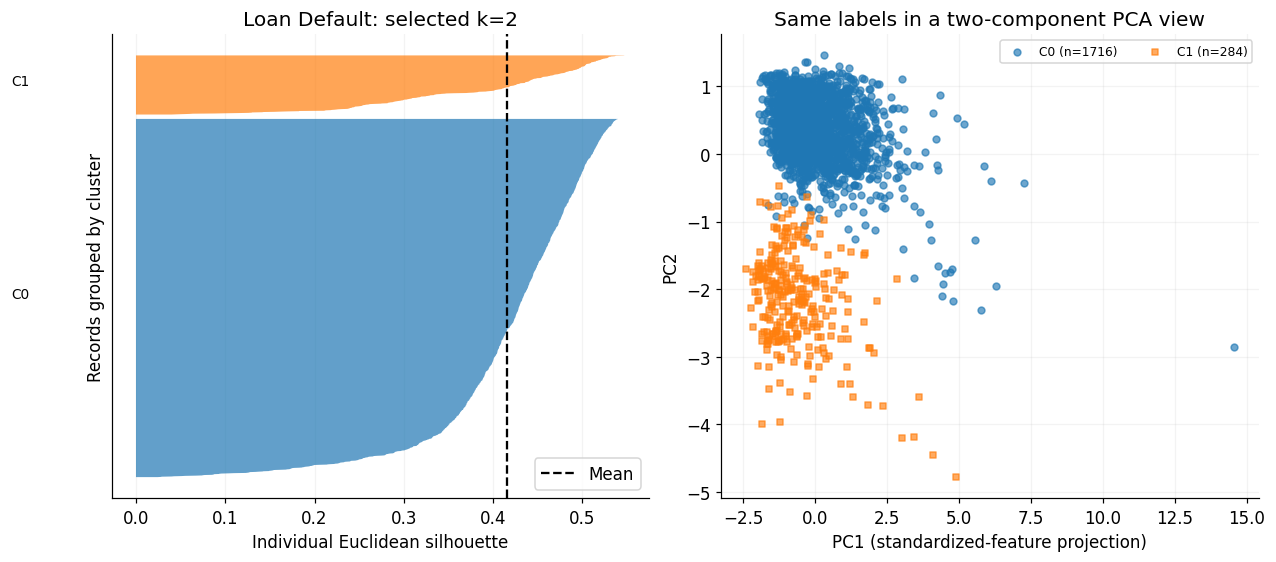

**0.0%** of records have negative silhouette: their mean distance to another cluster is smaller than within their assigned group. Overlap in PCA may reflect the projection, so assess it alongside full-space silhouettes.

**Selected k-means cluster profile.** Outcome fraction = recorded Status 1; descriptive only.

,n,outcome fraction,median loan_amount,median income,median Credit_Score,median term
cluster,,,,,,
0,1716,0.238,"316,500.000","5,580.000",707.000,360.000
1,284,0.236,"216,500.000","6,060.000",714.000,180.000


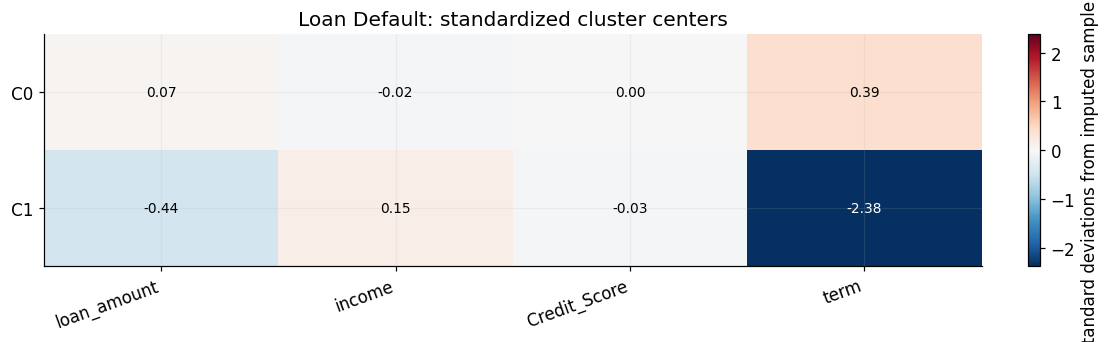

**Interpretation:** term shows the largest absolute standardized center (2.38 SD). Cluster sizes range from 284 to 1,716. Descriptive outcome fractions range from 23.6% to 23.8%; outcomes were not used to choose features, k, scaling or seed. These are in-sample associations, not risk predictions.

In [8]:
point_silhouette = silhouette_samples(Z, labels)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5), layout='constrained')
bottom = 0
for label in sorted(np.unique(labels)):
    values = np.sort(point_silhouette[labels == label])
    axes[0].fill_betweenx(np.arange(bottom, bottom+len(values)), 0, values, alpha=.7)
    axes[0].text(-.14, bottom+len(values)/2, f'C{label}', fontsize=9)
    bottom += len(values) + max(1, len(X)//100)
axes[0].axvline(point_silhouette.mean(), color='black', linestyle='--', label='Mean')
axes[0].set(title=f'{plot_label}: selected k={chosen_k}', xlabel='Individual Euclidean silhouette', ylabel='Records grouped by cluster', yticks=[])
axes[0].legend()
scatter_clusters(coords, labels, axes[1], 'Same labels in a two-component PCA view')
plt.show()
display(Markdown(f'**{np.mean(point_silhouette<0):.1%}** of records have negative silhouette: '
    'their mean distance to another cluster is smaller than within their assigned group. '
    'Overlap in PCA may reflect the projection, so assess it alongside full-space silhouettes.'))
profile_table = profile(labels, 'Selected k-means cluster profile')
centers = pd.DataFrame(km.cluster_centers_, columns=X.columns)
fig, ax = plt.subplots(figsize=(10, max(3, .5*chosen_k)), layout='constrained')
limit = max(1, np.abs(centers.to_numpy()).max())
im = ax.imshow(centers, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto')
ax.set(xticks=np.arange(X.shape[1]), xticklabels=X.columns, yticks=range(chosen_k),
       yticklabels=[f'C{i}' for i in range(chosen_k)], title=f'{plot_label}: standardized cluster centers')
plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
for i in range(chosen_k):
    for j in range(X.shape[1]):
        ax.text(j,i,f'{centers.iloc[i,j]:.2f}',ha='center',va='center',fontsize=9,
                color='white' if abs(centers.iloc[i,j])>.65*limit else 'black')
fig.colorbar(im, ax=ax, label='Standard deviations from imputed sample mean')
plt.show()
top_feature = centers.abs().max().idxmax()
display(Markdown(f'**Interpretation:** {top_feature} shows the largest absolute standardized center '
    f'({centers[top_feature].abs().max():.2f} SD). Cluster sizes range from '
    f'{profile_table.n.min():,} to {profile_table.n.max():,}. Descriptive outcome fractions range '
    f'from {profile_table["outcome fraction"].min():.1%} to {profile_table["outcome fraction"].max():.1%}; '
    'outcomes were not used to choose features, k, scaling or seed. These are in-sample associations, not risk predictions.'))
results.append({'Dataset': plot_label, 'n':len(X), 'k':chosen_k, 'elbow k':elbow_k,
    'silhouette':point_silhouette.mean(), 'negative fraction':np.mean(point_silhouette<0),
    'minimum seed ARI': min(row['ARI vs seed 42'] for row in stability),
    'smallest cluster':int(profile_table.n.min()), 'sample fingerprint':fingerprint})

## B. LendingClub resolved 2015 36-month loans

### B1. Reconstruct the source cohort

In [9]:
dataset_name = 'accepted_2007_to_2018Q4.csv'
outcome_label = 'charged off among resolved 2015 36-month loans'
USECOLS = ['id', 'loan_amnt', 'annual_inc', 'fico_range_low', 'fico_range_high',
           'dti', 'revol_util', 'open_acc', 'emp_length', 'earliest_cr_line',
           'issue_d', 'loan_status', 'term', 'home_ownership', 'purpose', 'verification_status']
rng = np.random.default_rng(SEED)
frame = pd.DataFrame()
all_rows = vintage_rows = short_term_rows = eligible_rows = 0
status_counts = pd.Series(dtype='int64')
for chunk in pd.read_csv(DATA_DIR / dataset_name, usecols=USECOLS, chunksize=150_000, low_memory=False):
    all_rows += len(chunk)
    cohort = chunk.loc[chunk['issue_d'].astype('str').str.endswith('2015')].copy()
    vintage_rows += len(cohort)
    cohort = cohort.loc[cohort['term'].str.strip().eq('36 months')]
    short_term_rows += len(cohort)
    status_counts = status_counts.add(cohort['loan_status'].value_counts(), fill_value=0)
    cohort = cohort.loc[cohort['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
    eligible_rows += len(cohort)
    if len(cohort):
        cohort['_priority'] = rng.random(len(cohort))
        frame = pd.concat([frame, cohort.nsmallest(SAMPLE_SIZE, '_priority')]).nsmallest(SAMPLE_SIZE, '_priority')
frame = frame.drop(columns='_priority').reset_index(drop=True)
assert frame['id'].notna().all() and frame['id'].is_unique
display(pd.Series({'source rows': all_rows, '2015 records': vintage_rows,
    '2015 36-month records': short_term_rows, 'resolved eligible records': eligible_rows,
    'excluded unresolved/other statuses': short_term_rows - eligible_rows,
    'uniform sample': len(frame)}, name='Resolved-outcome cohort'))
display(status_counts.astype(int).rename('2015 36-month records').to_frame())
X = pd.DataFrame({
    'log_loan_amount': np.log1p(frame['loan_amnt'].where(frame['loan_amnt'] > 0)),
    'log_annual_income': np.log1p(frame['annual_inc'].where(frame['annual_inc'] >= 0)),
    'fico_mid': (frame['fico_range_low'] + frame['fico_range_high']) / 2,
    'dti': frame['dti'].where(frame['dti'] >= 0),
    'revol_util': frame['revol_util'].where(frame['revol_util'] >= 0),
    'open_acc': frame['open_acc']})
numeric = list(X.columns)
categorical = ['home_ownership', 'purpose', 'verification_status']
for name in categorical:
    X[name] = frame[name].astype(object).where(frame[name].notna(), np.nan)
y = frame['loan_status'].eq('Charged Off').astype(int)
groups = None

source rows                           2260701
2015 records                           421095
2015 36-month records                  283173
resolved eligible records              283026
excluded unresolved/other statuses        147
uniform sample                          12000
Name: Resolved-outcome cohort, dtype: int64

,2015 36-month records
loan_status,
Charged Off,42132
Current,72
Fully Paid,240894
In Grace Period,9
Late (16-30 days),5
Late (31-120 days),61


### B2. Audit the shared clustering sample

In [10]:
# Use numeric features only: categorical one-hot block weights would add a separate geometry choice.
X = X[numeric].replace([np.inf, -np.inf], np.nan).reset_index(drop=True)
y = y.reset_index(drop=True)
indices = (X.sample(n=CLUSTER_SAMPLE, random_state=SEED).index.to_numpy()
           if len(X) > CLUSTER_SAMPLE else np.arange(len(X)))
X = X.iloc[indices].reset_index(drop=True)
y = y.iloc[indices].reset_index(drop=True)
assert not X.isna().all().any(), 'An entirely missing feature needs a documented decision.'
assert X.select_dtypes('number').shape[1] == X.shape[1]
imputer = SimpleImputer(strategy='median')
raw = imputer.fit_transform(X)
scaler = StandardScaler()
Z = scaler.fit_transform(raw)
assert np.isfinite(Z).all() and len(X) == len(y)
min_cluster = max(3, int(np.ceil(.01*len(X))))
plot_label = {'Loan_Default.csv':'Loan Default', 'accepted_2007_to_2018Q4.csv':'LendingClub',
              'bank_customers.csv':'Bank records'}[dataset_name]
fingerprint = hashlib.sha256(pd.util.hash_pandas_object(X, index=False).values.tobytes()).hexdigest()[:16]
display(pd.Series({'clustering records': len(X), 'numeric dimensions': X.shape[1],
    'duplicate feature rows': X.duplicated().sum(), 'minimum acceptable cluster size': min_cluster,
    'sample feature fingerprint': fingerprint}, name='Clustering sample'))
display(pd.DataFrame({'missing n': X.isna().sum(), 'median': X.median(),
    'minimum': X.min(), 'maximum': X.max(), 'SD before scaling': pd.DataFrame(raw, columns=X.columns).std()}))
pca = PCA(n_components=2, svd_solver='full')
coords = pca.fit_transform(Z)
display(Markdown(f'PCA shows **{pca.explained_variance_ratio_.sum():.1%}** of standardized variance. '
    'All clustering and scores use the full feature space, not this display projection.'))

clustering records                             2000
numeric dimensions                                6
duplicate feature rows                            0
minimum acceptable cluster size                  20
sample feature fingerprint         7fbf4b29f1965fd4
Name: Clustering sample, dtype: object

,missing n,median,minimum,maximum,SD before scaling
log_loan_amount,0,9.210,6.909,10.463,0.688
log_annual_income,0,11.013,9.035,13.422,0.564
fico_mid,0,687.000,662.000,842.000,30.817
dti,0,17.985,0.360,57.140,8.987
revol_util,0,51.350,0.000,118.100,24.316
open_acc,0,11.000,2.000,41.000,5.635


PCA shows **51.9%** of standardized variance. All clustering and scores use the full feature space, not this display projection.

### B3. Compare k, elbow and scaling

,representation,k,inertia,silhouette,clusters,noise fraction,smallest cluster,largest share
0,Unscaled,1,"3,306,877.552",NaN,1,0.000,2000,1.000
1,Unscaled,2,"1,854,985.327",0.414,2,0.000,568,0.716
2,Unscaled,3,"1,315,402.034",0.329,3,0.000,344,0.452
3,Unscaled,4,"1,021,111.255",0.318,4,0.000,167,0.346
4,Unscaled,5,"861,102.958",0.304,5,0.000,145,0.288
5,Unscaled,6,"757,066.056",0.272,6,0.000,144,0.242
6,Unscaled,7,"676,991.320",0.270,7,0.000,75,0.234
7,Unscaled,8,"621,668.586",0.266,8,0.000,72,0.186
8,Standard,1,"12,000.000",NaN,1,0.000,2000,1.000
9,Standard,2,"9,787.002",0.177,2,0.000,902,0.549


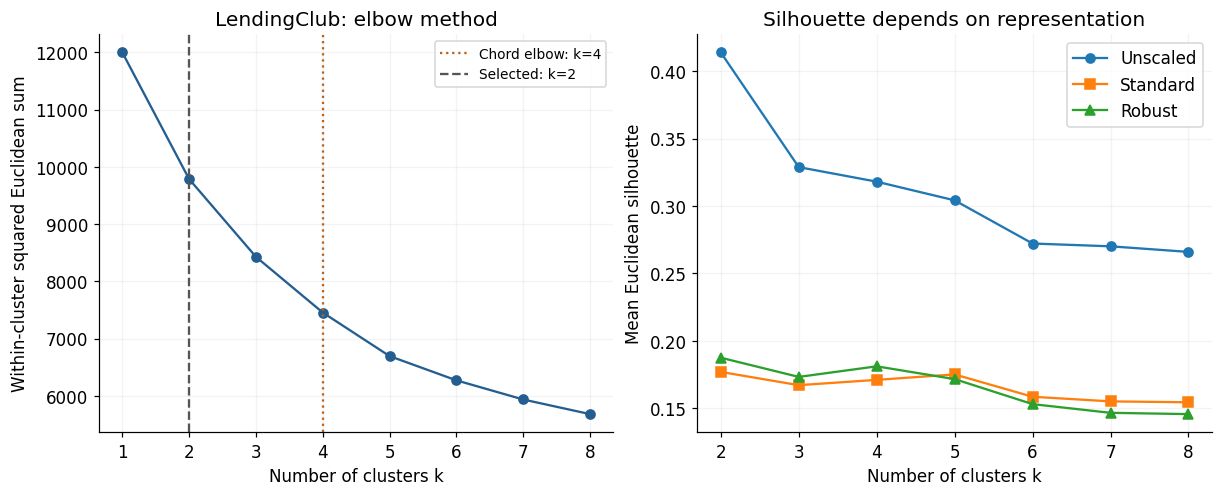

**Selection:** standard-scaled k=2, silhouette **0.177**, smallest cluster **902**; chord elbow suggests **k=4**. The largest eligible silhouette selects k; the elbow is a second diagnostic, not proof of a true number of groups. Scores across representations evaluate different geometries and cannot establish a universally best scaler.

In [11]:
representations = {'Unscaled': raw, 'Standard': Z, 'Robust': RobustScaler().fit_transform(raw)}
k_grid = range(1, 9)
k_rows, fitted = [], {}
for representation, data in representations.items():
    distances = pairwise_distances(data, metric='euclidean')
    np.fill_diagonal(distances, 0)
    for k in k_grid:
        model = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(data)
        fitted[(representation, k)] = model
        stats = cluster_stats(model.labels_)
        score = silhouette_score(distances, model.labels_, metric='precomputed') if k>1 else np.nan
        k_rows.append({'representation': representation, 'k': k, 'inertia': model.inertia_,
                       'silhouette': score, **stats})
k_table = pd.DataFrame(k_rows)
display(k_table.round(4))
standard = k_table.query("representation == 'Standard'").copy()
candidates = standard.query('k >= 2 and `smallest cluster` >= @min_cluster')
assert len(candidates), 'No supported standard-scaled candidate; revise the exploratory scope explicitly.'
chosen = candidates.sort_values(['silhouette','k'], ascending=[False,True]).iloc[0]
chosen_k = int(chosen['k'])
km = fitted[('Standard', chosen_k)]
labels = km.labels_
# Maximum vertical gap from a normalized endpoint chord: a reproducible elbow heuristic.
x_norm = (standard['k'].to_numpy()-1)/7
y_norm = (standard['inertia'].to_numpy()-standard['inertia'].iloc[-1])/(standard['inertia'].iloc[0]-standard['inertia'].iloc[-1])
elbow_k = int(standard.iloc[np.argmax((1-x_norm)-y_norm)]['k'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout='constrained')
axes[0].plot(standard['k'], standard['inertia'], 'o-', color='#245E91')
axes[0].axvline(elbow_k, linestyle=':', color='#B96520', label=f'Chord elbow: k={elbow_k}')
axes[0].axvline(chosen_k, linestyle='--', color='#555555', label=f'Selected: k={chosen_k}')
axes[0].set(title=f'{plot_label}: elbow method', xlabel='Number of clusters k', ylabel='Within-cluster squared Euclidean sum')
axes[0].legend(fontsize=9)
for name, marker in [('Unscaled','o'), ('Standard','s'), ('Robust','^')]:
    part = k_table.query('representation == @name and k >= 2')
    axes[1].plot(part['k'], part['silhouette'], marker=marker, label=name)
axes[1].set(title='Silhouette depends on representation', xlabel='Number of clusters k', ylabel='Mean Euclidean silhouette')
axes[1].legend()
plt.show()
display(Markdown(f'**Selection:** standard-scaled k={chosen_k}, silhouette **{chosen["silhouette"]:.3f}**, '
    f'smallest cluster **{int(chosen["smallest cluster"])}**; chord elbow suggests **k={elbow_k}**. '
    'The largest eligible silhouette selects k; the elbow is a second diagnostic, not proof of a true number of groups. '
    'Scores across representations evaluate different geometries and cannot establish a universally best scaler.'))

### B4. Check assignments and initialization sensitivity

In [12]:
# Hold k fixed to isolate scaling sensitivity from changes in cluster count.
scaling_rows = []
for name, data in representations.items():
    model = fitted[(name, chosen_k)]
    scaling_rows.append({'representation': name, 'fixed k': chosen_k,
        'own-space silhouette': safe_silhouette(data, model.labels_),
        'ARI vs Standard': adjusted_rand_score(labels, model.labels_), **cluster_stats(model.labels_)})
display(pd.DataFrame(scaling_rows).set_index('representation'))
# Expected contribution to pairwise squared distances is proportional to feature variance.
contributions = pd.Series(raw.var(axis=0), index=X.columns)
display((contributions/contributions.sum()).rename('raw squared-distance variance share').to_frame())
stability = []
for seed in [7, 21, 42, 84, 123]:
    repeat = KMeans(n_clusters=chosen_k, n_init=20, random_state=seed).fit(Z)
    stability.append({'seed': seed, 'inertia': repeat.inertia_,
                      'ARI vs seed 42': adjusted_rand_score(labels, repeat.labels_)})
display(pd.DataFrame(stability))
display(Markdown('ARI measures agreement after allowing cluster-number permutations. '
    'This check changes initialization on the same data; it does not measure stability under new samples.'))

# Explain surprisingly high robust-space silhouettes with the actual fitted scales.
robust_audit = RobustScaler().fit(raw)
iqr = np.quantile(raw,.75,axis=0)-np.quantile(raw,.25,axis=0)
robust_var = representations['Robust'].var(axis=0)
display(pd.DataFrame({'imputed IQR':iqr, 'RobustScaler divisor':robust_audit.scale_,
    'robust squared-distance variance share':robust_var/robust_var.sum()},index=X.columns))
raw_leader = contributions.idxmax()
robust_leader = X.columns[np.argmax(robust_var)]
display(Markdown(f'**Scaling finding:** {raw_leader} contributes '
    f'{contributions.max()/contributions.sum():.1%} of raw pairwise squared-distance variation; '
    f'{robust_leader} contributes {robust_var.max()/robust_var.sum():.1%} after robust scaling. '
    'A zero IQR uses a unit divisor, so a discrete feature can retain a large numerical range. '
    'A higher silhouette in that space may reflect dominant feature weighting rather than stronger multi-feature segments.'))


,fixed k,own-space silhouette,ARI vs Standard,clusters,noise fraction,smallest cluster,largest share
representation,,,,,,,
Unscaled,2,0.414,0.080,2,0.000,568,0.716
Standard,2,0.177,1.000,2,0.000,902,0.549
Robust,2,0.188,0.927,2,0.000,895,0.552


,raw squared-distance variance share
log_loan_amount,0.000
log_annual_income,0.000
fico_mid,0.574
dti,0.049
revol_util,0.357
open_acc,0.019


,seed,inertia,ARI vs seed 42
0,7,"9,787.002",1.000
1,21,"9,787.002",1.000
2,42,"9,787.002",1.000
3,84,"9,787.002",1.000
4,123,"9,787.043",0.996


ARI measures agreement after allowing cluster-number permutations. This check changes initialization on the same data; it does not measure stability under new samples.

,imputed IQR,RobustScaler divisor,robust squared-distance variance share
log_loan_amount,0.932,0.932,0.164
log_annual_income,0.716,0.716,0.188
fico_mid,40.000,40.000,0.179
dti,12.828,12.828,0.148
revol_util,37.625,37.625,0.126
open_acc,7.000,7.000,0.195


**Scaling finding:** fico_mid contributes 57.4% of raw pairwise squared-distance variation; open_acc contributes 19.5% after robust scaling. A zero IQR uses a unit divisor, so a discrete feature can retain a large numerical range. A higher silhouette in that space may reflect dominant feature weighting rather than stronger multi-feature segments.

### B5. Compare distance metrics

In [13]:
# K-means optimizes squared Euclidean distance. These metrics diagnose the same fixed labels.
metric_rows = []
for metric in ['euclidean', 'manhattan', 'cosine']:
    metric_rows.append({'metric': metric, 'same-label silhouette': silhouette_score(Z, labels, metric=metric)})
display(pd.DataFrame(metric_rows).set_index('metric'))
# Compare 5-neighbor sets for every record; remove the self index explicitly even under ties.
neighbor_sets = {}
for metric in ['euclidean','manhattan']:
    neighbors = NearestNeighbors(n_neighbors=6, metric=metric).fit(Z).kneighbors(Z, return_distance=False)
    neighbor_sets[metric] = [set(row[row != i][:5]) for i,row in enumerate(neighbors)]
overlap = np.mean([len(a & b)/5 for a,b in zip(neighbor_sets['euclidean'],neighbor_sets['manhattan'])])
display(Markdown(f'Euclidean and Manhattan 5-neighbor sets overlap by **{overlap:.1%}** on average. '
    'Manhattan sums absolute differences; Euclidean uses straight-line distance; cosine compares direction relative '
    'to the standardized origin. Changing the diagnostic does not refit k-means with another objective.'))

,same-label silhouette
metric,
euclidean,0.177
manhattan,0.190
cosine,0.308


Euclidean and Manhattan 5-neighbor sets overlap by **73.6%** on average. Manhattan sums absolute differences; Euclidean uses straight-line distance; cosine compares direction relative to the standardized origin. Changing the diagnostic does not refit k-means with another objective.

### B6. Inspect individual silhouettes and profiles

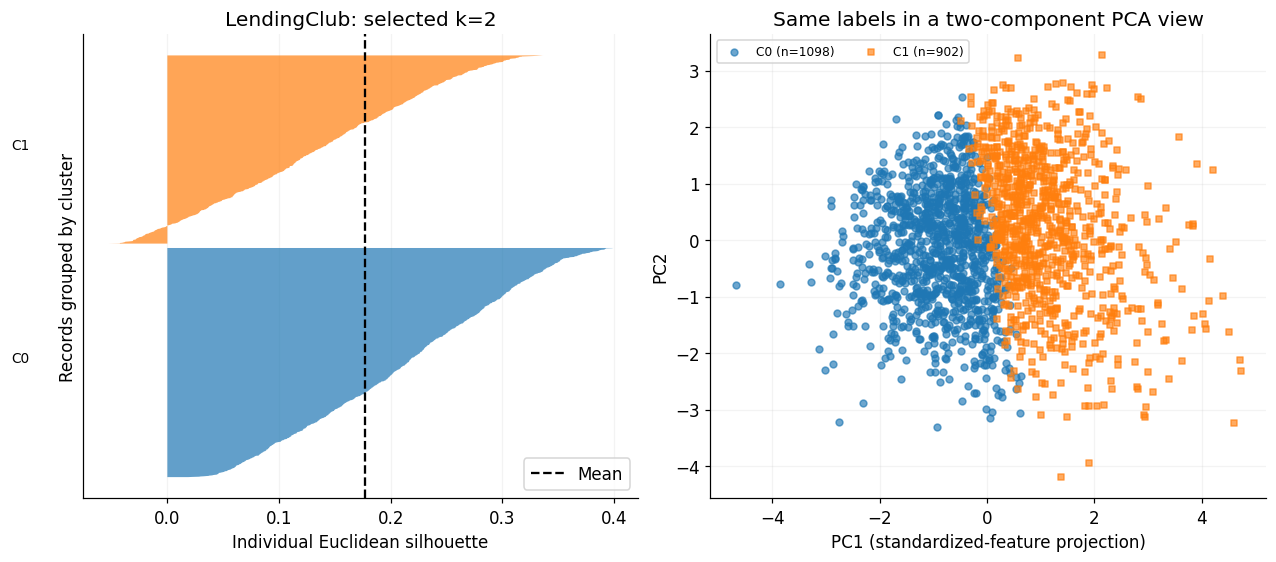

**4.3%** of records have negative silhouette: their mean distance to another cluster is smaller than within their assigned group. Overlap in PCA may reflect the projection, so assess it alongside full-space silhouettes.

**Selected k-means cluster profile.** Outcome fraction = charged off among resolved 2015 36-month loans; descriptive only.

,n,outcome fraction,median log_loan_amount,median log_annual_income,median fico_mid,median dti,median revol_util,median open_acc
cluster,,,,,,,,
0,1098,0.142,8.923,10.714,682.000,19.690,53.750,9.000
1,902,0.120,9.798,11.408,702.000,16.320,48.400,13.000


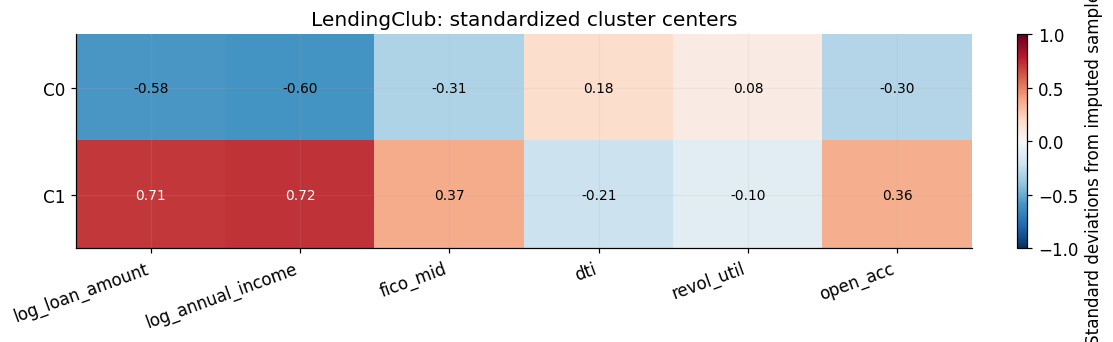

**Interpretation:** log_annual_income shows the largest absolute standardized center (0.72 SD). Cluster sizes range from 902 to 1,098. Descriptive outcome fractions range from 12.0% to 14.2%; outcomes were not used to choose features, k, scaling or seed. These are in-sample associations, not risk predictions.

In [14]:
point_silhouette = silhouette_samples(Z, labels)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5), layout='constrained')
bottom = 0
for label in sorted(np.unique(labels)):
    values = np.sort(point_silhouette[labels == label])
    axes[0].fill_betweenx(np.arange(bottom, bottom+len(values)), 0, values, alpha=.7)
    axes[0].text(-.14, bottom+len(values)/2, f'C{label}', fontsize=9)
    bottom += len(values) + max(1, len(X)//100)
axes[0].axvline(point_silhouette.mean(), color='black', linestyle='--', label='Mean')
axes[0].set(title=f'{plot_label}: selected k={chosen_k}', xlabel='Individual Euclidean silhouette', ylabel='Records grouped by cluster', yticks=[])
axes[0].legend()
scatter_clusters(coords, labels, axes[1], 'Same labels in a two-component PCA view')
plt.show()
display(Markdown(f'**{np.mean(point_silhouette<0):.1%}** of records have negative silhouette: '
    'their mean distance to another cluster is smaller than within their assigned group. '
    'Overlap in PCA may reflect the projection, so assess it alongside full-space silhouettes.'))
profile_table = profile(labels, 'Selected k-means cluster profile')
centers = pd.DataFrame(km.cluster_centers_, columns=X.columns)
fig, ax = plt.subplots(figsize=(10, max(3, .5*chosen_k)), layout='constrained')
limit = max(1, np.abs(centers.to_numpy()).max())
im = ax.imshow(centers, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto')
ax.set(xticks=np.arange(X.shape[1]), xticklabels=X.columns, yticks=range(chosen_k),
       yticklabels=[f'C{i}' for i in range(chosen_k)], title=f'{plot_label}: standardized cluster centers')
plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
for i in range(chosen_k):
    for j in range(X.shape[1]):
        ax.text(j,i,f'{centers.iloc[i,j]:.2f}',ha='center',va='center',fontsize=9,
                color='white' if abs(centers.iloc[i,j])>.65*limit else 'black')
fig.colorbar(im, ax=ax, label='Standard deviations from imputed sample mean')
plt.show()
top_feature = centers.abs().max().idxmax()
display(Markdown(f'**Interpretation:** {top_feature} shows the largest absolute standardized center '
    f'({centers[top_feature].abs().max():.2f} SD). Cluster sizes range from '
    f'{profile_table.n.min():,} to {profile_table.n.max():,}. Descriptive outcome fractions range '
    f'from {profile_table["outcome fraction"].min():.1%} to {profile_table["outcome fraction"].max():.1%}; '
    'outcomes were not used to choose features, k, scaling or seed. These are in-sample associations, not risk predictions.'))
results.append({'Dataset': plot_label, 'n':len(X), 'k':chosen_k, 'elbow k':elbow_k,
    'silhouette':point_silhouette.mean(), 'negative fraction':np.mean(point_silhouette<0),
    'minimum seed ARI': min(row['ARI vs seed 42'] for row in stability),
    'smallest cluster':int(profile_table.n.min()), 'sample fingerprint':fingerprint})

## C. Bank age and historical tenure

### C1. Reconstruct the source cohort

In [15]:
dataset_name = 'bank_customers.csv'
source_frame = pd.read_csv(DATA_DIR / dataset_name, usecols=lambda name: name != 'SSN')
AS_OF = pd.Timestamp('2026-09-26')
birth_text = source_frame['BirthDate'].astype('string').str.strip()
partial_birth = birth_text.str.fullmatch(r'\d{4}', na=False)
birth = pd.to_datetime(birth_text.mask(partial_birth), format='mixed', errors='coerce')
opened = pd.to_datetime(source_frame['AccountOpened'], format='mixed', errors='coerce')
valid_type = source_frame['AccountType'].isin(['checking', 'savings', 'cd'])
eligible = (birth.notna() & opened.notna() & birth.le(AS_OF) & opened.le(AS_OF)
            & opened.ge(birth) & valid_type)
# Reason flags overlap; the union, not their sum, determines exclusions.
display(pd.Series({'source records': len(source_frame),
    'missing/invalid/partial birth date': birth.isna().sum(),
    'missing/invalid opening date': opened.isna().sum(),
    'future opening date': opened.gt(AS_OF).sum(),
    'opening before exact birth date': opened.lt(birth).sum(),
    'missing/unrecognized account type': (~valid_type).sum(),
    'eligible records': eligible.sum(), 'excluded union': (~eligible).sum()}, name='Bank eligibility audit'))
frame = source_frame.loc[eligible].copy()
frame['age_years'] = (AS_OF - birth.loc[eligible]).dt.days / 365.25
frame['tenure_years'] = (AS_OF - opened.loc[eligible]).dt.days / 365.25
# Repeated AccountID values are conservatively grouped, even though this file
# does not document whether they represent shared accounts or data-quality issues.
frame['_group'] = frame['AccountID'].astype('string')
frame['_group'] = frame['_group'].fillna(pd.Series(
    ['missing_account_' + str(i) for i in frame.index], index=frame.index))
frame = frame.reset_index(drop=True)
groups = frame['_group']
assert len(frame) >= 20
display(frame['AccountType'].value_counts().rename('eligible records').to_frame())
# BirthDate, CustomerID, AccountID, and SSN are never displayed or used as model features.

outcome_label = 'checking account versus savings/CD'
X = frame[['age_years', 'tenure_years']].copy()
y = frame['AccountType'].eq('checking').astype(int)
numeric, categorical = list(X.columns), []

source records                        100
missing/invalid/partial birth date      3
missing/invalid opening date            1
future opening date                    59
opening before exact birth date         0
missing/unrecognized account type       1
eligible records                       39
excluded union                         61
Name: Bank eligibility audit, dtype: int64

,eligible records
AccountType,
checking,16
savings,15
cd,8


### C2. Audit the shared clustering sample

In [16]:
# Use numeric features only: categorical one-hot block weights would add a separate geometry choice.
X = X[numeric].replace([np.inf, -np.inf], np.nan).reset_index(drop=True)
y = y.reset_index(drop=True)
indices = (X.sample(n=CLUSTER_SAMPLE, random_state=SEED).index.to_numpy()
           if len(X) > CLUSTER_SAMPLE else np.arange(len(X)))
X = X.iloc[indices].reset_index(drop=True)
y = y.iloc[indices].reset_index(drop=True)
assert not X.isna().all().any(), 'An entirely missing feature needs a documented decision.'
assert X.select_dtypes('number').shape[1] == X.shape[1]
imputer = SimpleImputer(strategy='median')
raw = imputer.fit_transform(X)
scaler = StandardScaler()
Z = scaler.fit_transform(raw)
assert np.isfinite(Z).all() and len(X) == len(y)
min_cluster = max(3, int(np.ceil(.01*len(X))))
plot_label = {'Loan_Default.csv':'Loan Default', 'accepted_2007_to_2018Q4.csv':'LendingClub',
              'bank_customers.csv':'Bank records'}[dataset_name]
fingerprint = hashlib.sha256(pd.util.hash_pandas_object(X, index=False).values.tobytes()).hexdigest()[:16]
display(pd.Series({'clustering records': len(X), 'numeric dimensions': X.shape[1],
    'duplicate feature rows': X.duplicated().sum(), 'minimum acceptable cluster size': min_cluster,
    'sample feature fingerprint': fingerprint}, name='Clustering sample'))
display(pd.DataFrame({'missing n': X.isna().sum(), 'median': X.median(),
    'minimum': X.min(), 'maximum': X.max(), 'SD before scaling': pd.DataFrame(raw, columns=X.columns).std()}))
pca = PCA(n_components=2, svd_solver='full')
coords = pca.fit_transform(Z)
display(Markdown(f'PCA shows **{pca.explained_variance_ratio_.sum():.1%}** of standardized variance. '
    'All clustering and scores use the full feature space, not this display projection.'))

clustering records                               39
numeric dimensions                                2
duplicate feature rows                            0
minimum acceptable cluster size                   3
sample feature fingerprint         58d445e664cb6d2b
Name: Clustering sample, dtype: object

,missing n,median,minimum,maximum,SD before scaling
age_years,0,49.780,13.569,74.667,17.951
tenure_years,0,18.051,1.399,73.394,18.164


PCA shows **100.0%** of standardized variance. All clustering and scores use the full feature space, not this display projection.

In [17]:
display(pd.Series({'eligible bank records':len(frame), 'distinct account groups':groups.nunique(),
    'records beyond one per group':len(frame)-groups.nunique()}, name='Account repetition audit'))
display(Markdown('Repeated account groups retain their original row weight in this exploratory record-level study. '
    'With only 39 eligible records, bank clusters are a methods demonstration and do not establish population segments.'))

eligible bank records           39
distinct account groups         36
records beyond one per group     3
Name: Account repetition audit, dtype: int64

Repeated account groups retain their original row weight in this exploratory record-level study. With only 39 eligible records, bank clusters are a methods demonstration and do not establish population segments.

### C3. Compare k, elbow and scaling

,representation,k,inertia,silhouette,clusters,noise fraction,smallest cluster,largest share
0,Unscaled,1,"24,782.553",NaN,1,0.000,39,1.000
1,Unscaled,2,"11,134.271",0.490,2,0.000,11,0.718
2,Unscaled,3,"6,102.781",0.458,3,0.000,11,0.410
3,Unscaled,4,"4,430.468",0.448,4,0.000,4,0.410
4,Unscaled,5,"2,890.317",0.446,5,0.000,4,0.282
5,Unscaled,6,"2,346.992",0.433,6,0.000,4,0.205
6,Unscaled,7,"1,988.665",0.434,7,0.000,4,0.205
7,Unscaled,8,"1,679.244",0.452,8,0.000,4,0.205
8,Standard,1,78.000,NaN,1,0.000,39,1.000
9,Standard,2,35.153,0.488,2,0.000,11,0.718


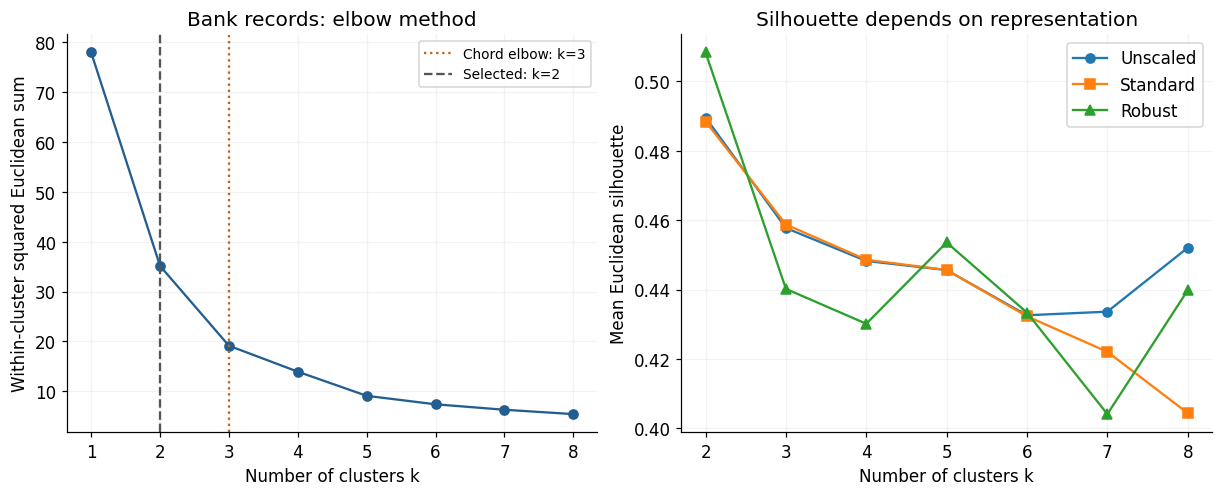

**Selection:** standard-scaled k=2, silhouette **0.488**, smallest cluster **11**; chord elbow suggests **k=3**. The largest eligible silhouette selects k; the elbow is a second diagnostic, not proof of a true number of groups. Scores across representations evaluate different geometries and cannot establish a universally best scaler.

In [18]:
representations = {'Unscaled': raw, 'Standard': Z, 'Robust': RobustScaler().fit_transform(raw)}
k_grid = range(1, 9)
k_rows, fitted = [], {}
for representation, data in representations.items():
    distances = pairwise_distances(data, metric='euclidean')
    np.fill_diagonal(distances, 0)
    for k in k_grid:
        model = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(data)
        fitted[(representation, k)] = model
        stats = cluster_stats(model.labels_)
        score = silhouette_score(distances, model.labels_, metric='precomputed') if k>1 else np.nan
        k_rows.append({'representation': representation, 'k': k, 'inertia': model.inertia_,
                       'silhouette': score, **stats})
k_table = pd.DataFrame(k_rows)
display(k_table.round(4))
standard = k_table.query("representation == 'Standard'").copy()
candidates = standard.query('k >= 2 and `smallest cluster` >= @min_cluster')
assert len(candidates), 'No supported standard-scaled candidate; revise the exploratory scope explicitly.'
chosen = candidates.sort_values(['silhouette','k'], ascending=[False,True]).iloc[0]
chosen_k = int(chosen['k'])
km = fitted[('Standard', chosen_k)]
labels = km.labels_
# Maximum vertical gap from a normalized endpoint chord: a reproducible elbow heuristic.
x_norm = (standard['k'].to_numpy()-1)/7
y_norm = (standard['inertia'].to_numpy()-standard['inertia'].iloc[-1])/(standard['inertia'].iloc[0]-standard['inertia'].iloc[-1])
elbow_k = int(standard.iloc[np.argmax((1-x_norm)-y_norm)]['k'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout='constrained')
axes[0].plot(standard['k'], standard['inertia'], 'o-', color='#245E91')
axes[0].axvline(elbow_k, linestyle=':', color='#B96520', label=f'Chord elbow: k={elbow_k}')
axes[0].axvline(chosen_k, linestyle='--', color='#555555', label=f'Selected: k={chosen_k}')
axes[0].set(title=f'{plot_label}: elbow method', xlabel='Number of clusters k', ylabel='Within-cluster squared Euclidean sum')
axes[0].legend(fontsize=9)
for name, marker in [('Unscaled','o'), ('Standard','s'), ('Robust','^')]:
    part = k_table.query('representation == @name and k >= 2')
    axes[1].plot(part['k'], part['silhouette'], marker=marker, label=name)
axes[1].set(title='Silhouette depends on representation', xlabel='Number of clusters k', ylabel='Mean Euclidean silhouette')
axes[1].legend()
plt.show()
display(Markdown(f'**Selection:** standard-scaled k={chosen_k}, silhouette **{chosen["silhouette"]:.3f}**, '
    f'smallest cluster **{int(chosen["smallest cluster"])}**; chord elbow suggests **k={elbow_k}**. '
    'The largest eligible silhouette selects k; the elbow is a second diagnostic, not proof of a true number of groups. '
    'Scores across representations evaluate different geometries and cannot establish a universally best scaler.'))

### C4. Check assignments and initialization sensitivity

In [19]:
# Hold k fixed to isolate scaling sensitivity from changes in cluster count.
scaling_rows = []
for name, data in representations.items():
    model = fitted[(name, chosen_k)]
    scaling_rows.append({'representation': name, 'fixed k': chosen_k,
        'own-space silhouette': safe_silhouette(data, model.labels_),
        'ARI vs Standard': adjusted_rand_score(labels, model.labels_), **cluster_stats(model.labels_)})
display(pd.DataFrame(scaling_rows).set_index('representation'))
# Expected contribution to pairwise squared distances is proportional to feature variance.
contributions = pd.Series(raw.var(axis=0), index=X.columns)
display((contributions/contributions.sum()).rename('raw squared-distance variance share').to_frame())
stability = []
for seed in [7, 21, 42, 84, 123]:
    repeat = KMeans(n_clusters=chosen_k, n_init=20, random_state=seed).fit(Z)
    stability.append({'seed': seed, 'inertia': repeat.inertia_,
                      'ARI vs seed 42': adjusted_rand_score(labels, repeat.labels_)})
display(pd.DataFrame(stability))
display(Markdown('ARI measures agreement after allowing cluster-number permutations. '
    'This check changes initialization on the same data; it does not measure stability under new samples.'))

# Explain surprisingly high robust-space silhouettes with the actual fitted scales.
robust_audit = RobustScaler().fit(raw)
iqr = np.quantile(raw,.75,axis=0)-np.quantile(raw,.25,axis=0)
robust_var = representations['Robust'].var(axis=0)
display(pd.DataFrame({'imputed IQR':iqr, 'RobustScaler divisor':robust_audit.scale_,
    'robust squared-distance variance share':robust_var/robust_var.sum()},index=X.columns))
raw_leader = contributions.idxmax()
robust_leader = X.columns[np.argmax(robust_var)]
display(Markdown(f'**Scaling finding:** {raw_leader} contributes '
    f'{contributions.max()/contributions.sum():.1%} of raw pairwise squared-distance variation; '
    f'{robust_leader} contributes {robust_var.max()/robust_var.sum():.1%} after robust scaling. '
    'A zero IQR uses a unit divisor, so a discrete feature can retain a large numerical range. '
    'A higher silhouette in that space may reflect dominant feature weighting rather than stronger multi-feature segments.'))


,fixed k,own-space silhouette,ARI vs Standard,clusters,noise fraction,smallest cluster,largest share
representation,,,,,,,
Unscaled,2,0.490,1.000,2,0.000,11,0.718
Standard,2,0.488,1.000,2,0.000,11,0.718
Robust,2,0.508,1.000,2,0.000,11,0.718


,raw squared-distance variance share
age_years,0.494
tenure_years,0.506


,seed,inertia,ARI vs seed 42
0,7,35.153,1.000
1,21,35.153,1.000
2,42,35.153,1.000
3,84,35.153,1.000
4,123,35.153,1.000


ARI measures agreement after allowing cluster-number permutations. This check changes initialization on the same data; it does not measure stability under new samples.

,imputed IQR,RobustScaler divisor,robust squared-distance variance share
age_years,28.664,28.664,0.390
tenure_years,23.198,23.198,0.610


**Scaling finding:** tenure_years contributes 50.6% of raw pairwise squared-distance variation; tenure_years contributes 61.0% after robust scaling. A zero IQR uses a unit divisor, so a discrete feature can retain a large numerical range. A higher silhouette in that space may reflect dominant feature weighting rather than stronger multi-feature segments.

### C5. Compare distance metrics

In [20]:
# K-means optimizes squared Euclidean distance. These metrics diagnose the same fixed labels.
metric_rows = []
for metric in ['euclidean', 'manhattan', 'cosine']:
    metric_rows.append({'metric': metric, 'same-label silhouette': silhouette_score(Z, labels, metric=metric)})
display(pd.DataFrame(metric_rows).set_index('metric'))
# Compare 5-neighbor sets for every record; remove the self index explicitly even under ties.
neighbor_sets = {}
for metric in ['euclidean','manhattan']:
    neighbors = NearestNeighbors(n_neighbors=6, metric=metric).fit(Z).kneighbors(Z, return_distance=False)
    neighbor_sets[metric] = [set(row[row != i][:5]) for i,row in enumerate(neighbors)]
overlap = np.mean([len(a & b)/5 for a,b in zip(neighbor_sets['euclidean'],neighbor_sets['manhattan'])])
display(Markdown(f'Euclidean and Manhattan 5-neighbor sets overlap by **{overlap:.1%}** on average. '
    'Manhattan sums absolute differences; Euclidean uses straight-line distance; cosine compares direction relative '
    'to the standardized origin. Changing the diagnostic does not refit k-means with another objective.'))

,same-label silhouette
metric,
euclidean,0.488
manhattan,0.503
cosine,0.573


Euclidean and Manhattan 5-neighbor sets overlap by **90.8%** on average. Manhattan sums absolute differences; Euclidean uses straight-line distance; cosine compares direction relative to the standardized origin. Changing the diagnostic does not refit k-means with another objective.

### C6. Inspect individual silhouettes and profiles

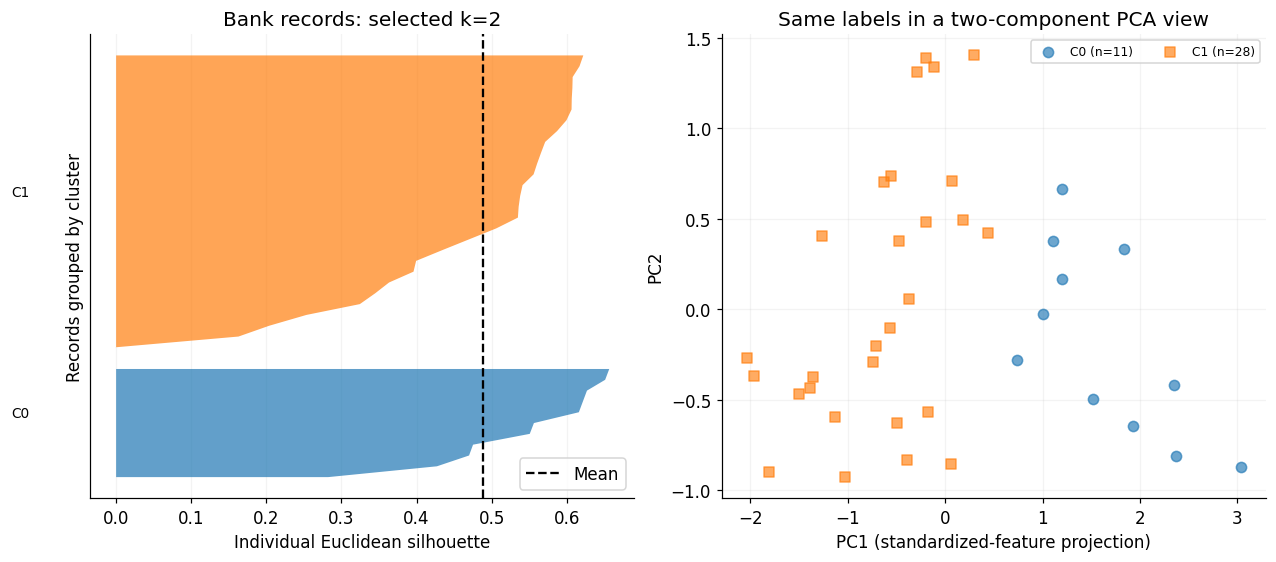

**2.6%** of records have negative silhouette: their mean distance to another cluster is smaller than within their assigned group. Overlap in PCA may reflect the projection, so assess it alongside full-space silhouettes.

**Selected k-means cluster profile.** Outcome fraction = checking account versus savings/CD; descriptive only.

,n,outcome fraction,median age_years,median tenure_years
cluster,,,,
0,11,0.273,66.007,42.894
1,28,0.464,37.802,14.137


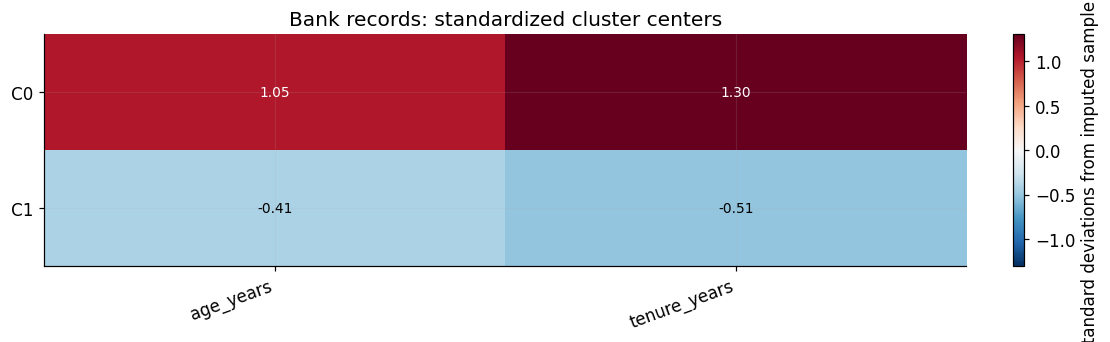

**Interpretation:** tenure_years shows the largest absolute standardized center (1.30 SD). Cluster sizes range from 11 to 28. Descriptive outcome fractions range from 27.3% to 46.4%; outcomes were not used to choose features, k, scaling or seed. These are in-sample associations, not risk predictions.

In [21]:
point_silhouette = silhouette_samples(Z, labels)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5), layout='constrained')
bottom = 0
for label in sorted(np.unique(labels)):
    values = np.sort(point_silhouette[labels == label])
    axes[0].fill_betweenx(np.arange(bottom, bottom+len(values)), 0, values, alpha=.7)
    axes[0].text(-.14, bottom+len(values)/2, f'C{label}', fontsize=9)
    bottom += len(values) + max(1, len(X)//100)
axes[0].axvline(point_silhouette.mean(), color='black', linestyle='--', label='Mean')
axes[0].set(title=f'{plot_label}: selected k={chosen_k}', xlabel='Individual Euclidean silhouette', ylabel='Records grouped by cluster', yticks=[])
axes[0].legend()
scatter_clusters(coords, labels, axes[1], 'Same labels in a two-component PCA view')
plt.show()
display(Markdown(f'**{np.mean(point_silhouette<0):.1%}** of records have negative silhouette: '
    'their mean distance to another cluster is smaller than within their assigned group. '
    'Overlap in PCA may reflect the projection, so assess it alongside full-space silhouettes.'))
profile_table = profile(labels, 'Selected k-means cluster profile')
centers = pd.DataFrame(km.cluster_centers_, columns=X.columns)
fig, ax = plt.subplots(figsize=(10, max(3, .5*chosen_k)), layout='constrained')
limit = max(1, np.abs(centers.to_numpy()).max())
im = ax.imshow(centers, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto')
ax.set(xticks=np.arange(X.shape[1]), xticklabels=X.columns, yticks=range(chosen_k),
       yticklabels=[f'C{i}' for i in range(chosen_k)], title=f'{plot_label}: standardized cluster centers')
plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
for i in range(chosen_k):
    for j in range(X.shape[1]):
        ax.text(j,i,f'{centers.iloc[i,j]:.2f}',ha='center',va='center',fontsize=9,
                color='white' if abs(centers.iloc[i,j])>.65*limit else 'black')
fig.colorbar(im, ax=ax, label='Standard deviations from imputed sample mean')
plt.show()
top_feature = centers.abs().max().idxmax()
display(Markdown(f'**Interpretation:** {top_feature} shows the largest absolute standardized center '
    f'({centers[top_feature].abs().max():.2f} SD). Cluster sizes range from '
    f'{profile_table.n.min():,} to {profile_table.n.max():,}. Descriptive outcome fractions range '
    f'from {profile_table["outcome fraction"].min():.1%} to {profile_table["outcome fraction"].max():.1%}; '
    'outcomes were not used to choose features, k, scaling or seed. These are in-sample associations, not risk predictions.'))
results.append({'Dataset': plot_label, 'n':len(X), 'k':chosen_k, 'elbow k':elbow_k,
    'silhouette':point_silhouette.mean(), 'negative fraction':np.mean(point_silhouette<0),
    'minimum seed ARI': min(row['ARI vs seed 42'] for row in stability),
    'smallest cluster':int(profile_table.n.min()), 'sample fingerprint':fingerprint})

## Takeaways across all three datasets

In [22]:
summary = pd.DataFrame(results).set_index('Dataset')
assert len(summary) == 3
display(summary)

,n,k,elbow k,silhouette,negative fraction,minimum seed ARI,smallest cluster,sample fingerprint
Dataset,,,,,,,,
Loan Default,2000,2,4,0.416,0.000,1.000,284,de56ac5c17ea8ad6
LendingClub,2000,2,4,0.177,0.043,0.996,902,7fbf4b29f1965fd4
Bank records,39,2,3,0.488,0.026,1.000,11,58d445e664cb6d2b


## Milestone Two synthesis and limitations

Preserve the population, numeric feature definitions, scaling, selection rules, cluster-size distributions and any noise coverage when compiling Milestone Two. Cluster numbers are arbitrary labels, not risk ranks. Outcome profiles are exploratory associations on the selected data; they are neither held-out classifier accuracy nor causal evidence. Financial units differ across datasets, and log variables stay in log1p units in the profile tables.

Before treating these as useful segments, repeat the analysis on other samples and vintages, assess feature weighting/outlier handling, verify account/borrower identities, and test whether stable groups answer a concrete project question. Initialization stability alone does not establish sampling stability. DBSCAN density depends on sample size; eps from 2,000 rows should not be transferred unchanged to the full source. HAC has quadratic pairwise costs, so the bounded sample is intentional. The small bank cohort and repeated accounts prevent population conclusions.

The Milestone Two rubric was not provided. No course submission or Yellowdig posting has been performed.

## Yellowdig — draft initial post

**Source:** scikit-learn developers, [Selecting the number of clusters with silhouette analysis on KMeans clustering](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html) (accessed November 22, 2026).

I consider this a high-quality source because it is maintained by the library developers and combines an explanation with runnable code and visual diagnostics. It shows why the average score should be considered alongside the silhouette distribution and cluster sizes. In my capstone, I pair this diagnostic with the inertia elbow and scaling comparisons rather than assuming that the largest score proves a natural number of borrower groups. The worked example uses synthetic data, so its numerical results do not validate my financial datasets.

**Peer response prompt:** After reading a classmate’s actual source, identify its distance/scaling assumptions, reproduce or inspect one example, and discuss whether its cluster-size or silhouette evidence supports the interpretation. Include the peer’s specific evidence before posting; this is a prompt, not a completed reply.

## Sources and reproducibility

**Data:** the three original CSVs under `DATA/`, with the same source-loading/cohort logic as Week 9. Each dataset section prints counts, exclusions, missingness, feature ranges and a sampled-feature fingerprint. No web data supply the results.

**Methods:** the primary documentation linked in the method guide and Yellowdig section was consulted November 22, 2026. Versioned scikit-learn 1.8 API references match the pinned environment; stable example/guide and SciPy pages may describe newer versions. Installed versions are printed at setup. All method explanations are paraphrased, and all numerical findings are computed locally.

**Run:** from the repository, use `python3 -m jupyter nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=1200 "Week 10.ipynb"`. Install the existing pinned `requirements-notebooks.txt` into your environment if needed. The original CSVs are required. Every analytical output and the final results table recompute from the cells; the top summary describes the delivered saved run and should be revised if inputs/settings change.